# Assignment 27 — Week 2, Day 1
## Topic: Python — User-Defined Exceptions

**Objective:** Complete the exercise on user-defined exception handling in Python.

**Reference:** https://www.programiz.com/python-programming/user-defined-exception

**Diagram:** A user-defined exception is a new class that inherits from the built-in Exception class.

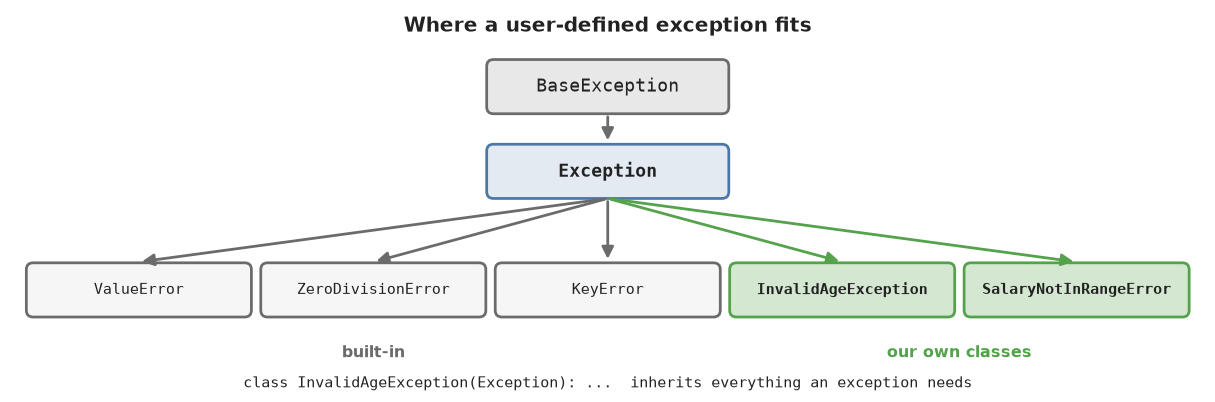

**Built-in exceptions are classes**

In [1]:
print(ValueError.__mro__)
print(issubclass(ZeroDivisionError, Exception))

(<class 'ValueError'>, <class 'Exception'>, <class 'BaseException'>, <class 'object'>)
True


**Explanation:** Every built-in exception is a class. __mro__ shows that ValueError inherits from Exception, which inherits from BaseException. A custom exception is made the same way.

**Define a custom exception**

In [2]:
class InvalidAgeException(Exception):
    """Raised when the input value is less than 18"""
    pass

print(issubclass(InvalidAgeException, Exception))

True


**Explanation:** A custom exception is a class that inherits from Exception. pass means it adds nothing new, but it now has its own name that can be raised and caught.

**Diagram:** The four steps to use a custom exception.

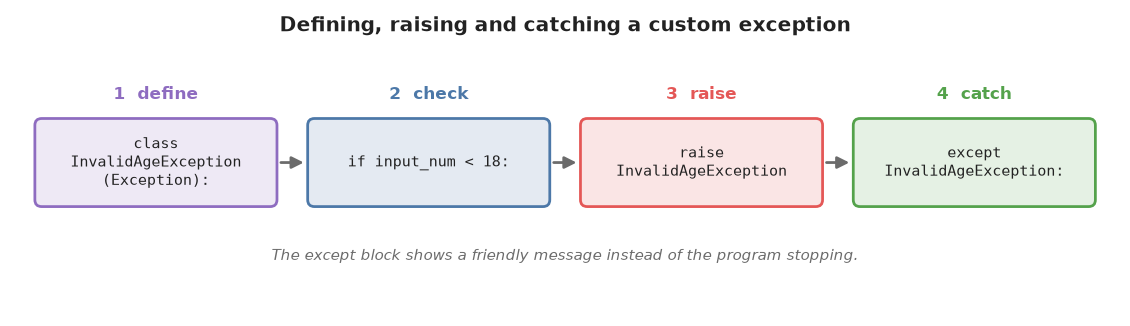

**Raise and catch the custom exception**

In [3]:
class InvalidAgeException(Exception):
    """Raised when the input value is less than 18"""
    pass

number = 18

for input_num in [20, 15]:
    try:
        if input_num < number:
            raise InvalidAgeException
        else:
            print(input_num, "-> Eligible to Vote")
    except InvalidAgeException:
        print(input_num, "-> Exception occurred: Invalid Age")

20 -> Eligible to Vote
15 -> Exception occurred: Invalid Age


**Explanation:** When the age is below 18, the code raises InvalidAgeException, and the matching except block catches it. A fixed list of ages is used so the notebook runs without asking for input.

**Raise a custom exception with a message**

In [4]:
class InvalidAgeException(Exception):
    pass

def check_age(age):
    if age < 18:
        raise InvalidAgeException(f"Age {age} is below the voting age of 18")
    return "Eligible to vote"

for age in [25, 12]:
    try:
        print(age, "->", check_age(age))
    except InvalidAgeException as error:
        print(age, "->", "Error:", error)

25 -> Eligible to vote
12 -> Error: Age 12 is below the voting age of 18


**Explanation:** A message can be passed when raising the exception. as error stores the exception object, and printing it shows the message.

**Diagram:** The parts of a customised exception class.

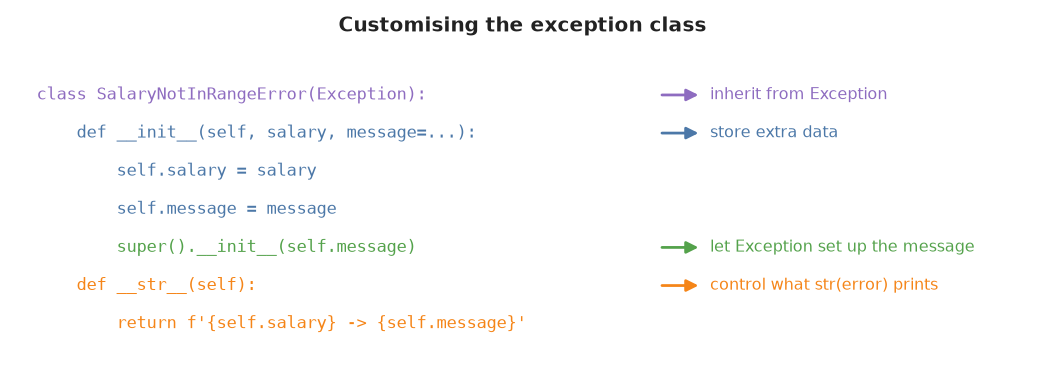

**Customise the exception class**

In [5]:
class SalaryNotInRangeError(Exception):
    """Exception raised for errors in the input salary.

    Attributes:
        salary -- input salary which caused the error
        message -- explanation of the error
    """

    def __init__(self, salary, message="Salary is not in (5000, 15000) range"):
        self.salary = salary
        self.message = message
        super().__init__(self.message)


for salary in [8000, 2000]:
    try:
        if not 5000 < salary < 15000:
            raise SalaryNotInRangeError(salary)
        print(salary, "-> Salary accepted")
    except SalaryNotInRangeError as error:
        print(error.salary, "->", error)

8000 -> Salary accepted
2000 -> Salary is not in (5000, 15000) range


**Explanation:** __init__ stores extra data (the salary) on the exception and sets a default message. super().__init__() passes the message to the Exception class, so printing the error shows it.

**Override __str__**

In [6]:
class SalaryNotInRangeError(Exception):
    def __init__(self, salary, message="Salary is not in (5000, 15000) range"):
        self.salary = salary
        self.message = message
        super().__init__(self.message)

    def __str__(self):
        return f"{self.salary} -> {self.message}"


try:
    raise SalaryNotInRangeError(2000)
except SalaryNotInRangeError as error:
    print(error)

2000 -> Salary is not in (5000, 15000) range


**Explanation:** __str__ decides what is shown when the exception is printed. Here it includes both the salary and the message.

**A family of custom exceptions**

In [7]:
class BankError(Exception):
    """Base class for all bank errors"""

class InsufficientFundsError(BankError):
    pass

class InvalidAmountError(BankError):
    pass

def withdraw(balance, amount):
    if amount <= 0:
        raise InvalidAmountError(f"Amount must be positive, got {amount}")
    if amount > balance:
        raise InsufficientFundsError(f"Cannot withdraw {amount}, balance is {balance}")
    return balance - amount

for amount in [300, -50, 900]:
    try:
        print("New balance:", withdraw(500, amount))
    except BankError as error:
        print(type(error).__name__ + ":", error)

New balance: 200
InvalidAmountError: Amount must be positive, got -50
InsufficientFundsError: Cannot withdraw 900, balance is 500


**Explanation:** Several custom exceptions can share a base class. Catching the base class (BankError) handles all of them, while type(error).__name__ shows which one actually happened.

## Observation

- A user-defined exception is a class that inherits from Exception.
- It is raised with raise and caught with except, just like a built-in exception.
- A message can be passed when raising it and read with as error.
- __init__ can store extra data, and super().__init__() sets the message.
- __str__ controls how the exception is printed.
- Custom exceptions can share a base class so they can be caught together.

## Conclusion

User-defined exceptions give clear names to the errors that matter in a specific program, such as an invalid age or a salary out of range. This makes code easier to read and lets each kind of error be handled in its own way.